# **👨🏻‍🎓 Learning Objective 👨🏻‍🎓**


## **Objective**

- Run Atlas in VS Code and follow its interface and backend functions.
- Combine document retrieval with validated table calculations.
- Check answers for correct sources, figures, units and reporting periods.

---

## **Introduction**

Northstar Systems now extends **Atlas** into company research. Building on earlier GenAI and RAG lessons, this Gradio application combines document evidence with pandas calculations to answer questions about **Apple, Microsoft and Alphabet**. **DeepSeek** proposes calculation plans and generates answers from the collected evidence.

---

## **Theme**

- **Company research through document retrieval and table analysis.**

---

## **Primary Goals**

- Understand how `app.py` connects to `backend.py`.
- Trace uploaded files through retrieval, calculation and answer generation.
- Verify answers using the displayed evidence.

---

## **Pre-requisites**

- Basic Python, pandas, LangChain and RAG knowledge.
- Python **3.11/3.12**, VS Code and internet access.
- A valid **DeepSeek API key** with available credit.

# **📖 Learning Material 📖**


## Section 1: Set Up and Open the Code


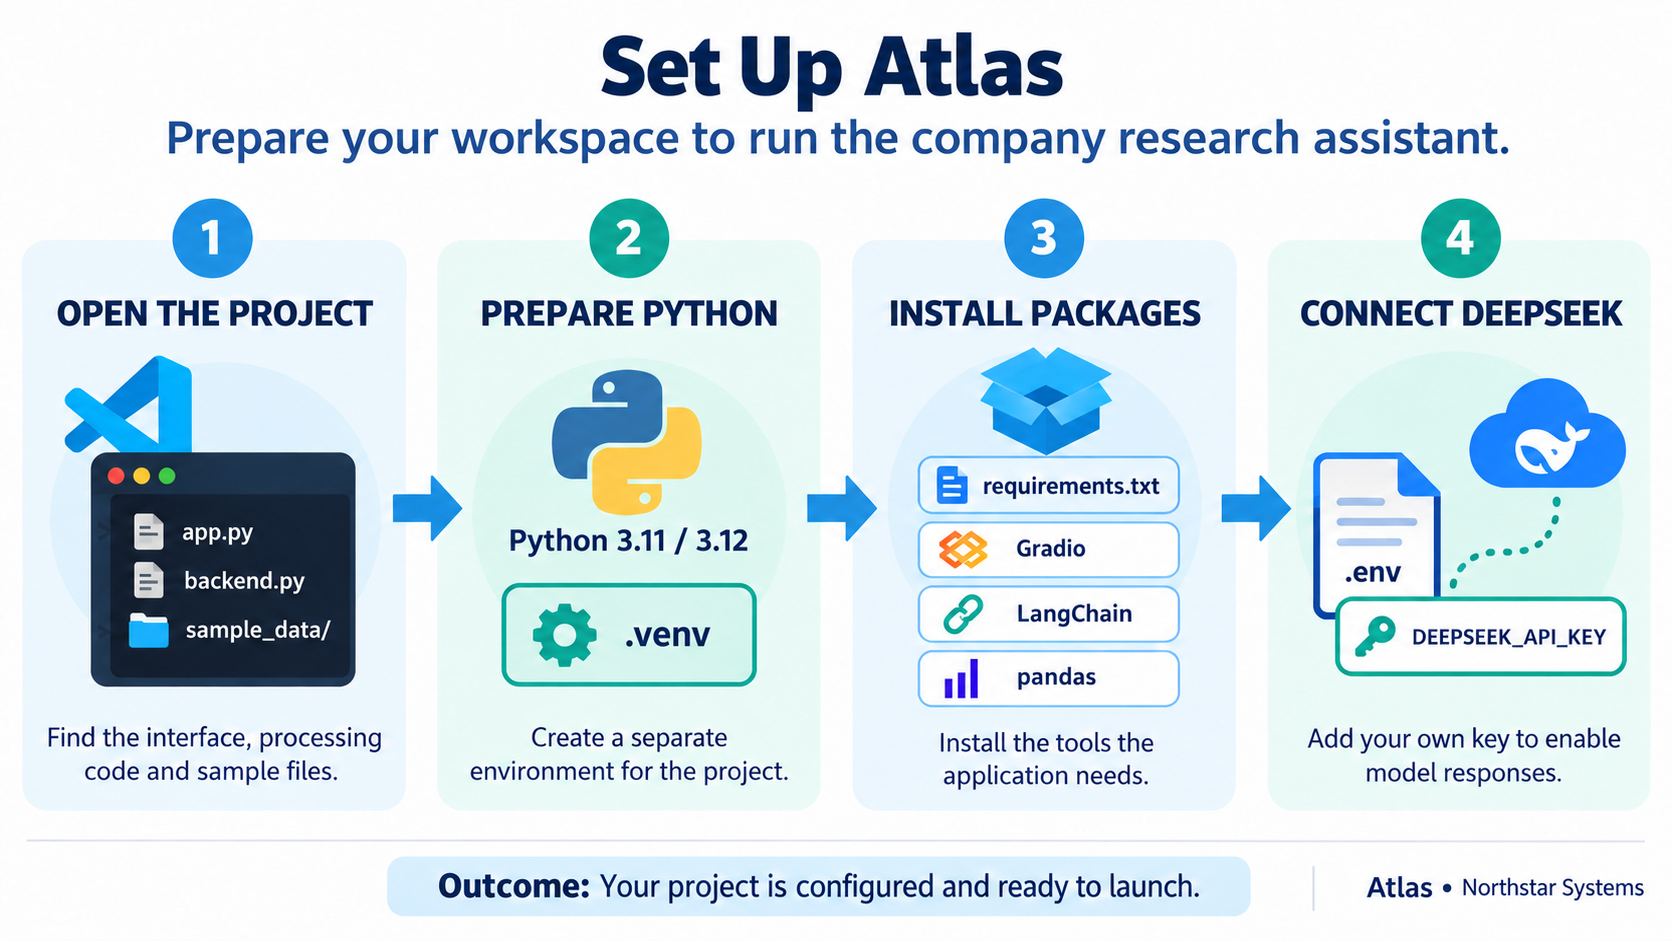



### 1. Prepare the project

- Extract the project and open its folder in VS Code.
- Use Python 3.11 or 3.12, 64-bit.
- Open `app.py` and `backend.py` side by side.
- Keep `sample_data/` unchanged; it contains three company summaries and three financial tables.
- This notebook is a reading guide. Run the commands below in the VS Code terminal.



### 2. Install packages

Windows PowerShell:

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install --upgrade pip
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

macOS/Linux:

```bash
python3 -m venv .venv
.venv/bin/python -m pip install --upgrade pip
.venv/bin/python -m pip install -r requirements.txt
```

- Select `.venv` using **Python: Select Interpreter** in VS Code.
- `langchain-deepseek` connects LangChain to DeepSeek.
- Gradio builds the interface; pandas/openpyxl read tables; pypdf reads PDF text.
- Local sentence-transformer models provide embeddings and optional reranking.



### 3. Configure `.env`

```dotenv
DEEPSEEK_API_KEY=replace_with_your_key
DEEPSEEK_MODEL=deepseek-flash
DEEPSEEK_API_BASE=https://api.deepseek.com
EMBEDDING_MODEL=sentence-transformers/all-MiniLM-L6-v2
RERANK_MODEL=cross-encoder/ms-marco-MiniLM-L-6-v2
```

- Replace only the key placeholder with your own DeepSeek key.
- The bundled `.env` contains no real key; `.gitignore` excludes it from Git.
- Commit `.env.example` as the configuration template.
- Restart the app after changing settings: `chat_model()` caches the client.
- Both chains use DeepSeek in non-thinking mode; embeddings and reranking remain local.
- The first retrieval can take longer while local models download.

## Section 2: Follow the Functions

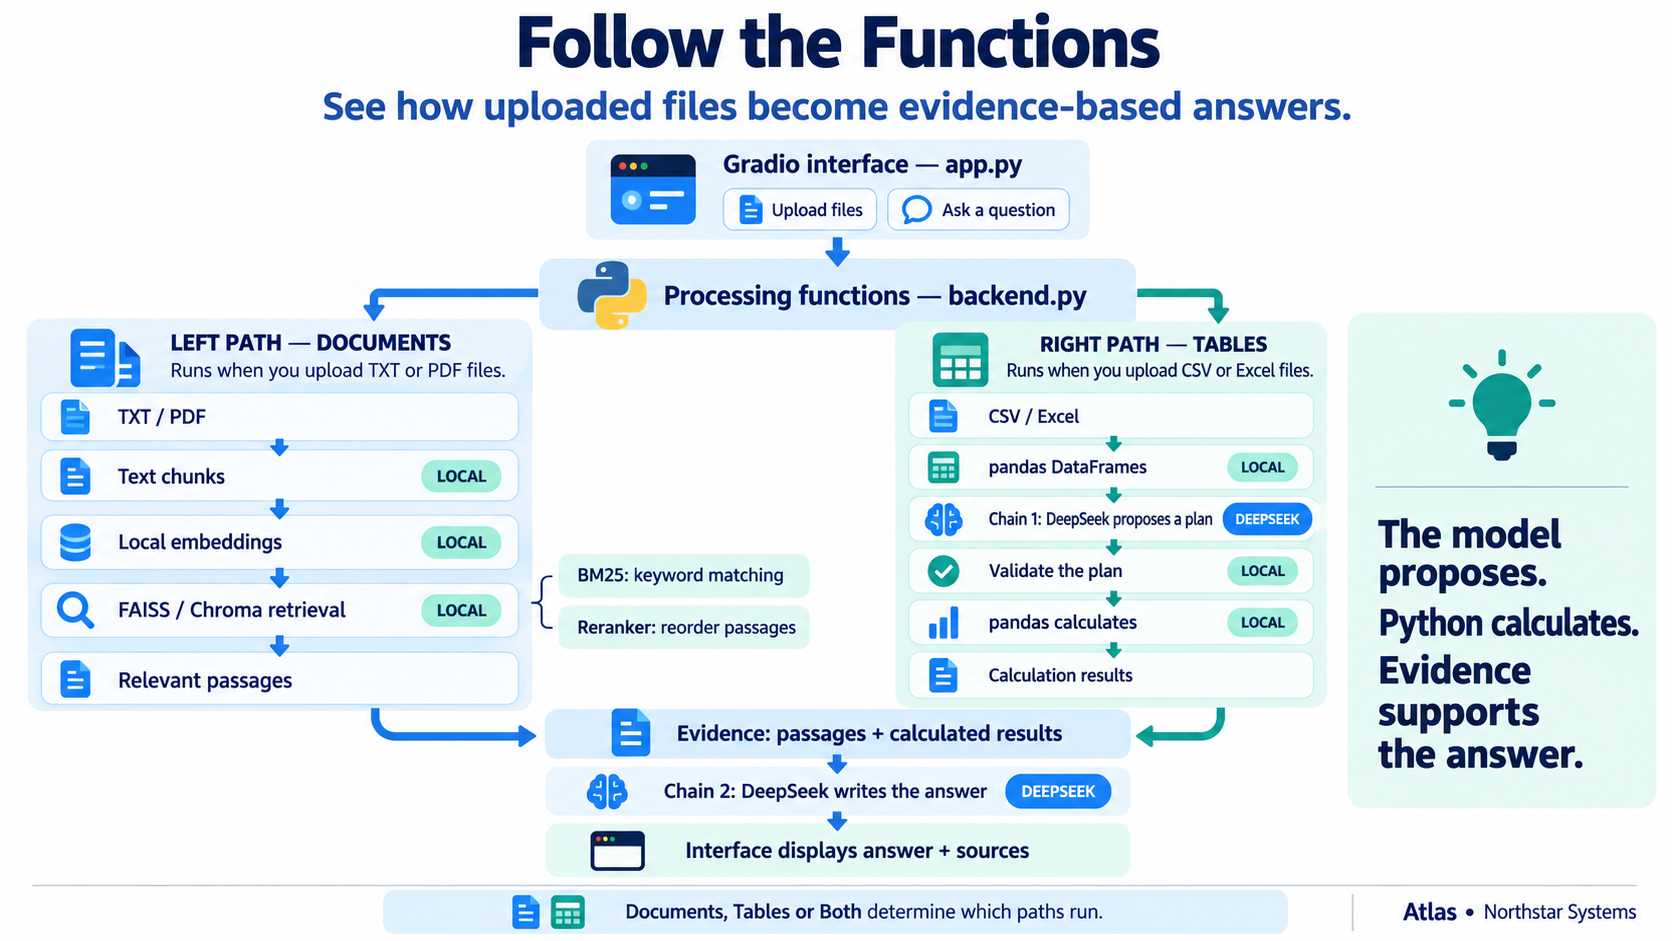



### 1. Read `app.py`: the interface

- **Imports:** only the required backend functions and `MAX_BYTES` are imported. `inventory` is imported as `get_inventory` to avoid clashing with the UI table.
- **`ui_error(exc)`:** converts a failure into a Gradio error; unexpected failures are logged.
- **`add_ui(...)`:** reads uploaded file bytes → calls `add_files()` → calls `get_inventory()` → refreshes company choices and file rows.
- **`ask_ui(...)`:** calls `answer_question()` → displays the answer, document evidence and calculations.
- **`reset_ui(key)`:** calls `clear_workspace()` and resets the interface.
- **`clear_conversation()`:** clears only the displayed conversation and evidence; files remain available.
- **`ui.load(create_workspace, ...)`:** creates a workspace when the interface loads.
- **Button bindings:** `.click()` and `.submit()` connect user actions to these callbacks.
- **Launch:** `ui.queue().launch()` starts the local browser interface. There are no custom API endpoints.


### 2. Read `backend.py`: workspace and upload functions

- **`create_workspace()`:** creates a unique session ID and empty storage.
- **`workspace(key)`:** finds the session data or raises an error for an invalid ID.
- **`discard_indexes(ws)`:** removes cached indexes when uploaded content changes.
- **`clear_workspace(key)`:** removes uploaded files, tables, documents and indexes for that session.
- **`numeric(series)`:** converts numeric-looking values into numbers; invalid values become missing.
- **`clean_table(frame)`:** tidies table headers/rows and converts suitable columns to numbers.
- **`add_files(...)`:** validates the whole upload batch; TXT/PDF become Documents, CSV/XLSX become DataFrames. Stores the batch only after validation succeeds.
- **`inventory(key)`:** returns company choices and file/table details for the interface.
- **Metadata:** company, filename, reporting basis and page/sheet details keep evidence attached to its source.


### 3. Follow a TXT and CSV upload

- Upload `apple_summary.txt` and `apple_financials.csv` under **Apple**.
- `add_ui()` reads bytes and sends them to `add_files()`.
- TXT text becomes a LangChain `Document`; CSV rows become a pandas DataFrame.
- Both remain in the workspace. Tables are not embedded or chunked.
- Indexing happens when document retrieval is first requested, not during upload.
- XLSX follows the table path, with a separate table for each valid worksheet.




### 4. Read the document retrieval functions

- **`embedding_model()`:** loads and caches the local embedding model.
- **`reranking_model()`:** loads and caches the local cross-encoder.
- **`tokenize(text)`:** splits text into searchable words for BM25.
- **`build_index(...)`:** splits documents into 900-character chunks with 150-character overlap; stores embeddings in FAISS or Chroma and prepares BM25.
- **`retrieve(...)`:** searches each selected company, optionally combines keyword ranks, optionally reranks, and returns source-labelled evidence.
- **Both checkboxes off:** dense vector similarity search only; up to six passages per company.
- **BM25 on:** combines dense and keyword rankings using reciprocal rank fusion.
- **Reranking on:** scores question/passage pairs and retains up to three passages per company.
- **Store behavior:** FAISS uses its default L2 distance; Chroma is configured with cosine distance. Embeddings are normalized.




### 5. Read the table-analysis functions

- **`chat_model()`:** reads DeepSeek settings from `.env` and returns the shared model client.
- **`Filter`, `Task`, `AnalysisPlan`:** Pydantic schemas describe allowed filters and calculation tasks.
- **`describe_tables(tables)`:** supplies table IDs, column types, reporting notes and the first three rows to the planner.
- **`analyze(...)`:** builds the planning prompt → calls DeepSeek → parses the plan → calls `execute_plan()`.
- **`execute_plan(tables, plan)`:** validates tables/columns/filters, runs permitted pandas operations, and returns calculation evidence.
- **Operations:** `sum`, `mean`, `min`, `max`, `count`; supported filters and up to two grouping columns.
- **Example:** for Apple FY2024 revenue, the plan selects the Apple table, filters `fiscal_year == 2024`, and sums `net_sales_usd_m`.
- The model proposes the plan; pandas calculates. No generated Python or SQL is executed.





### 6. Connect the two LangChain chains

- **Planning chain in `analyze()`:** `ChatPromptTemplate | chat_model() | PydanticOutputParser(AnalysisPlan)`.
- **Execution after chain 1:** `execute_plan()` calculates results locally.
- **Answer chain in `answer_question()`:** `ChatPromptTemplate | chat_model() | StrOutputParser()`.
- `|` passes each component's output into the next component.
- Pydantic validates the returned JSON locally; provider-enforced structured output is not enabled.
- Request retries handle some request failures; they do not repair an invalid plan automatically.





### 7. Read `answer_question()` last

- Validates the question, selected companies and settings.
- Calls `retrieve()` for Documents/Both and `analyze()` for Tables/Both.
- Returns an unavailable response when both evidence lists are empty.
- Otherwise sends the question and collected evidence through the answer chain.
- Returns `answer`, `documents`, `calculations` and settings to `ask_ui()`.
- Questions are standalone: displayed chat history is not sent to DeepSeek.

## Section 3: Run and Check the Results


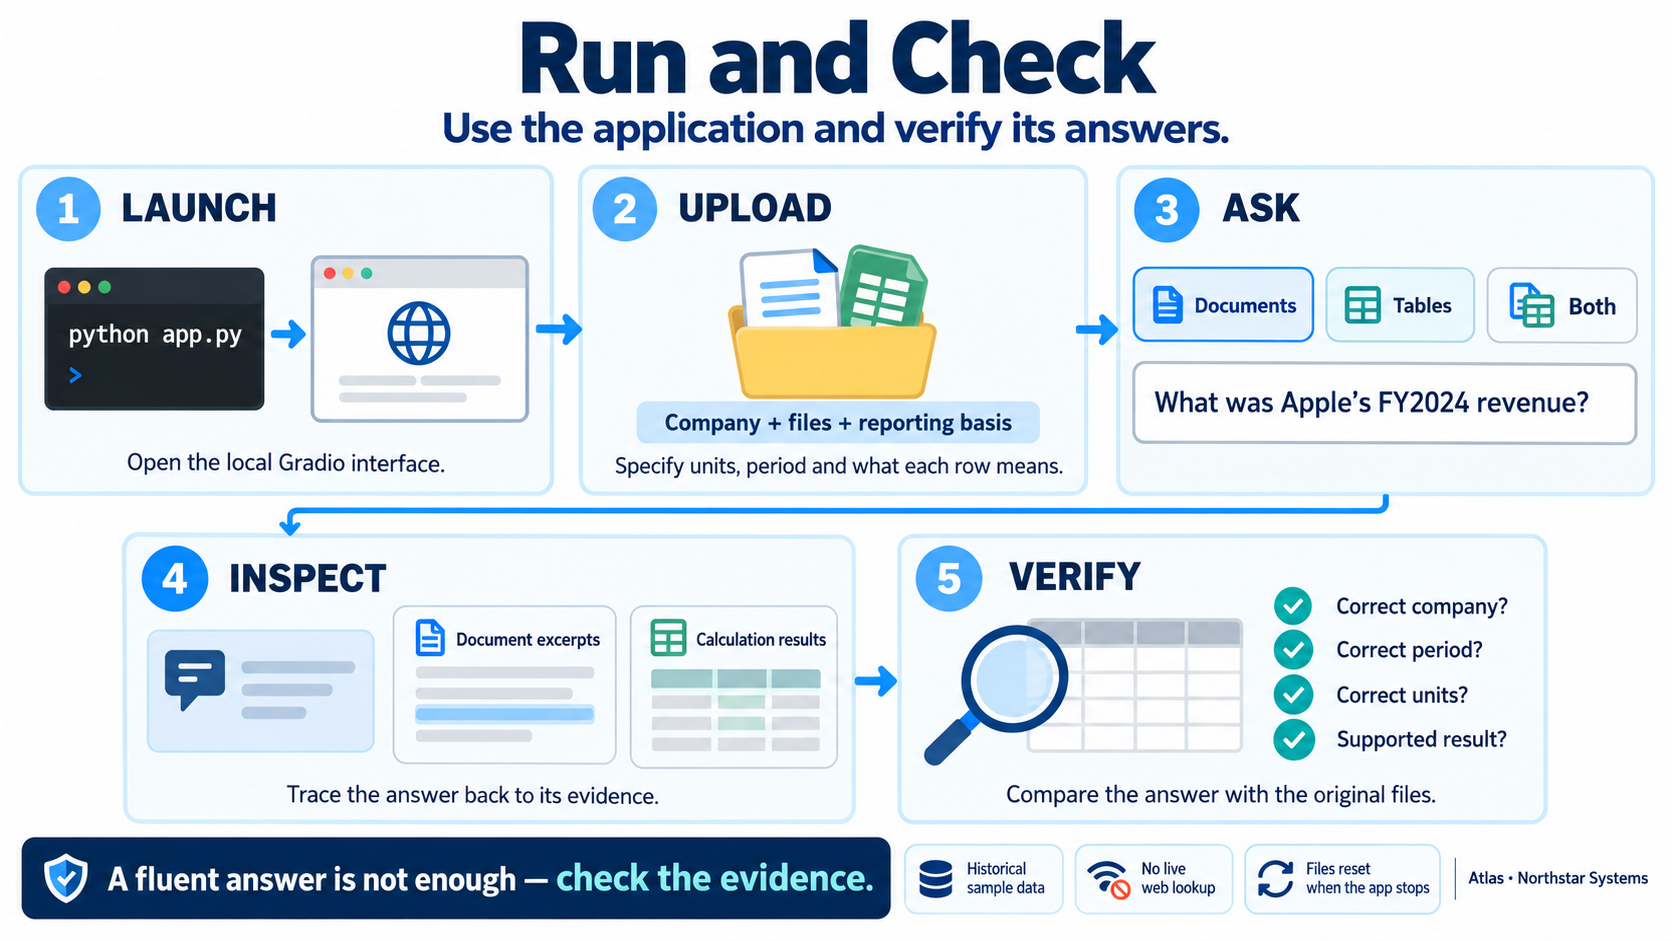


### 1. Start Atlas

Windows:

```powershell
.\.venv\Scripts\python.exe app.py
```

macOS/Linux:

```bash
.venv/bin/python app.py
```

- Open **http://127.0.0.1:7860/**; keep the terminal running.
- Upload each company's document/table pair separately.
- Enter its reporting basis before clicking **Add company files**.
- Choose companies and an evidence source, then ask a complete question.
- Expand **Inspect evidence** to trace the answer back to files and calculations.



### 2. Use the supplied samples

| Company label | Document | Table | Year / period-end columns | Revenue / net-income columns |
|---|---|---|---|---|
| Apple | `apple_summary.txt` | `apple_financials.csv` | `fiscal_year` / `year_end` | `net_sales_usd_m` / `net_income_usd_m` |
| Microsoft | `microsoft_summary.txt` | `microsoft_financials.xlsx` | `reporting_year` / `period_close` | `total_revenue_musd` / `profit_after_tax_musd` |
| Alphabet | `alphabet_summary.txt` | `alphabet_financials.xlsx` | `calendar_year` / `closing_date` | `revenues_us_millions` / `net_earnings_us_millions` |

The column names intentionally differ. The summary files explain their meanings. All monetary columns use **USD millions**, and each row contains consolidated annual results. The tables also include operating income and R&D expense.

**Reporting basis** means a short description of how to interpret a table: currency, scale, period, what one row represents and any column meanings that need clarification. It is required for CSV/XLSX uploads. Paste the appropriate note below; each fits the 300-character limit.

**Apple**

> USD millions; consolidated FY2022–FY2024; one row per fiscal year ending near September. net_sales_usd_m=revenue; net_income_usd_m=net income; operating_income_usd_m=operating income; research_development_usd_m=R&D. Preserve year_end; not calendar-aligned.

**Microsoft**

> USD millions; consolidated FY2022–FY2024; one row per fiscal year ending June 30. total_revenue_musd=revenue; profit_after_tax_musd=net income; earnings_from_operations_musd=operating income; rd_spend_musd=R&D. Preserve period_close; not calendar-aligned.

**Alphabet**

> USD millions; consolidated calendar years 2022–2024; one row per year ending December 31. revenues_us_millions=revenue; net_earnings_us_millions=net income; income_from_operations_us_millions=operating income; rnd_expense_us_millions=R&D. Preserve closing_date.

The notes guide interpretation; they do not rename columns or convert currencies. Keep the original dates. Comparing reported FY2024 figures is possible with a fiscal-period caveat; calling those figures an aligned calendar-year comparison is inaccurate.

### 3. Try these checks

- **Documents:** “What businesses does Apple operate?” Check the cited summary excerpt.
- **Tables:** “What was Apple's FY2024 revenue?” Expect **391,035 USD millions** from the supplied CSV.
- **Both:** “Compare FY2024 revenue and business activities for Apple, Microsoft and Alphabet. Keep each period-end date.” Check both evidence panels.
- Turn BM25 and reranking off, then on; compare retrieved passages for the same question.
- Clear conversation and ask again: files should remain. Clear uploaded files: the inventory should become empty.
- Ask for a current share price absent from the files; the assistant should identify the missing evidence.



### 4. Know the limits

- Files and indexes live in memory and disappear when Python stops.
- DeepSeek receives relevant excerpts and table descriptions/results; it needs internet access and a valid account key.
- Scanned PDFs need a separate OCR step. No live web lookup, table joins or stock forecasting is implemented.
- The historical samples cover 2022–2024; different fiscal year ends must remain visible.
- Microsoft’s sample 2023 R&D figure has a known source-data discrepancy; inspect the original source before relying on it.
- If setup fails, check the selected Python environment and run `python -m pip check` using that environment.
- For key/model errors, inspect `.env` and restart. For an invalid calculation plan, simplify the question and inspect the error.

# 💡**Try It Yourself**💡

## Activities

- Trace one upload from `add_ui()` to `inventory()` in the code.
- Trace one document question and one table question; identify where DeepSeek is called.
- Upload a different monthly sales CSV and describe its currency, period and one-row meaning.
- Ask for a supported sum or mean; verify it manually in the CSV.

## Summary

- `app.py` handles interactions; `backend.py` handles data and answers.
- Documents use retrieval; tables use validated pandas calculations.
- DeepSeek proposes table plans and writes answers from evidence.

## Additional Resources

- [DeepSeek API documentation](https://api-docs.deepseek.com/)
- [DeepSeek thinking-mode configuration](https://api-docs.deepseek.com/guides/thinking_mode/)
- [LangChain ChatDeepSeek reference](https://reference.langchain.com/python/langchain-deepseek/chat_models/ChatDeepSeek)
- [Project repository](https://github.com/almabetter-school-ds/AI_Company_Assistant)
- [Gradio documentation](https://www.gradio.app/docs)



## Build a Similar Project from Scratch with AI

Copy this prompt into an AI assistant:

```text
Act as a Python developer. Create a complete beginner-friendly VS Code project
called Atlas, a company research assistant built by the fictional Northstar
Systems. Use Python 3.11/3.12, Gradio, LangChain and DeepSeek.

Deliver app.py, backend.py, requirements.txt, .env.example, .gitignore, README.md,
a concise student notebook and sample_data/. Keep application logic in the two
Python files. Add short comments explaining why each main step is needed.

Requirements:
1. app.py imports only the backend functions/constants it actually uses. Avoid
   name collisions between imported functions and Gradio components.
2. Use langchain-deepseek and ChatDeepSeek. Read DEEPSEEK_API_KEY,
   DEEPSEEK_MODEL and DEEPSEEK_API_BASE from .env. Verify the current provider
   documentation before selecting the default model. Use non-thinking mode.
   Never include a real key; ignore .env in Git.
3. Let users upload PDF/TXT/CSV/XLSX under company labels and enter reporting
   notes covering units, periods and what each table row represents.
4. Keep isolated in-memory workspaces. Validate sizes/types/table dimensions;
   reject invalid upload batches without leaving partial data behind.
5. TXT/PDF become Documents with source metadata. Chunk text at 900 characters
   with 150 overlap. Use local normalized MiniLM embeddings and selectable
   FAISS/Chroma, optional BM25 rank fusion and optional cross-encoder reranking.
6. CSV/XLSX stay as pandas DataFrames. Use a LangChain prompt/model/Pydantic
   parser chain to propose restricted plans. Validate table IDs, columns,
   filters and operations before pandas executes sum/mean/min/max/count.
   Do not execute model-generated Python or SQL. Report missing values.
7. Support Documents, Tables and Both. A second prompt/model/string-parser
   chain writes an answer from retrieved excerpts and calculated evidence.
   Preserve citations, units, company labels and fiscal periods. Acknowledge
   missing information rather than inventing figures.
8. Display uploaded-file inventory, answer, document evidence and calculation
   evidence. Include clear-conversation and clear-upload buttons. State that
   displayed history is not sent to the model.
9. Call Python functions directly from Gradio. Do not create custom REST API
   routes or a separate FastAPI service. Disable Gradio client API exposure
   using settings compatible with the pinned Gradio version.
10. Provide small clearly labelled synthetic company samples, or use attached
    samples unchanged. Never present invented data as real company accounts.
11. The notebook should have a brief introduction, learning objectives, three
    concise learning-material sections (setup, code walkthrough, run/review),
    function explanations in points, flowcharts, exercises and resources.
    Do not add a Session Flow section.
12. Give Windows and macOS/Linux setup commands. Verify dependency compatibility,
    imports, callback wiring, sample loading and calculations. Clearly state
    which tests used mocked model responses and which used a live API.

Give every file in full with its filename, explain the two chains and provide
simple manual checks. Keep the implementation readable and avoid unnecessary abstractions or extra services.
```